# Lens refraction and stigmatic imaging

A lens redirects a beam across **two** dielectric faces, and the emerging wave
forms a finite focal spot. We construct a plane entrance face and a spherical
exit face, visualize their refracted rays, then calculate the meridional and
focal vector fields. The longitudinal component appears naturally after focusing.

The library composes explicit homogeneous and interface operators:

$$E_{out}=R_{\xi_2}Q^{-1}_{n_i,\Sigma}TQ_{n_0,\Sigma}R_{\xi}E_{in}.$$

`PlanarASM` is $R$; `SurfaceTransport.forward` is $Q$, evaluating the
angular spectrum at the actual surface height. Its inverse solves for the
outgoing plane spectrum from the two tangential electric components. $T$ uses
the local normal and incident eikonal direction. The sequence repeats at each
face. `solution.evaluate()` uses only the resulting homogeneous angular
spectrum, including Maxwell-consistent longitudinal electric and magnetic fields.

$Q^{-1}$ is **not** $Q$ with a negative height on a variable-height surface.
The FFT cell is periodic, so sampling, padding and the angular cutoff need
convergence checks. Fresnel transmission remains a local high-frequency model;
we report both inverse residuals and reconstructed field/flux errors below.
Returning reflections and rim scattering are not part of this forward model.

The second experiment constructs a Cartesian oval from conjugates through its
GOTS parameters in the collimated-input limit. It replaces only the exit face,
keeping the same vertex curvature, aperture, central thickness, materials, input
beam and observation coordinates.

**Explore:** radius of curvature, clear aperture, thickness, beam waist and input
polarization. SI metres are passed to the API; figures use µm.

**Wide-aperture comparison.** The radius is now $48\lambda_0$ and the Gaussian
waist is also $48\lambda_0$, so the aberrated outer rays carry appreciable light.
The earlier radius $24\lambda_0$ with waist $22\lambda_0$ emphasized the nearly
paraxial center, where the two shapes should give similar fields. Both lenses
now use central thickness $20\lambda_0$ so the enlarged spherical face does not
intersect the entrance plane. The shared vertex curvature is unchanged.

The shared Gaussian pupil is smoothly tapered over its outer $8\lambda_0$.
This is an explicit illumination change from a hard-edged pupil, applied to both
lenses. It makes sampling convergence easier to distinguish from pixelization
of a circular discontinuity. Set the taper width to zero only with a new grid
and angular-band convergence study.

**FFT cell.** The periodic cell is $128\lambda_0$ wide at $0.8\lambda_0$ spacing.
A separate study at fixed spacing compared cells of 128, 256, 384, 512 and
$768\lambda_0$ on the meridional map: the $128\lambda_0$ field differs from the
$768\lambda_0$ one by at most $6\cdot10^{-4}$ of the peak, so periodic replicas do
not affect these figures. The padding check at the end compares $128\lambda_0$
with $192\lambda_0$.

In [1]:
import inspect
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import vecdiff_general as optics
from vecdiff_general.visualization import plot_polarization

# Catch an older package or a kernel that cached the pre-operator API.
_project_roots = [
    parent
    for base in (Path.cwd(),)
    for parent in (base, *base.parents)
    if (parent / "general/src/vecdiff_general/__init__.py").exists()
]
_expected_package = (
    (_project_roots[0] / "general/src/vecdiff_general/__init__.py").resolve()
    if _project_roots
    else None
)
_loaded_package = Path(optics.__file__).resolve()
_parameters = tuple(inspect.signature(optics.propagate_interfaces).parameters)
if (
    _expected_package is not None and _loaded_package != _expected_package
) or _parameters[:3] != ("source", "system", "grid"):
    raise RuntimeError(
        f"This kernel loaded vecdiff_general from {_loaded_package} with "
        f"propagate_interfaces{inspect.signature(optics.propagate_interfaces)}. "
        "Select 'Logos Optics (project interpreter)', restart the kernel, and run all cells."
    )
%matplotlib inline

plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "figure.dpi": 180,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 11,
    }
)

um = 1e-6
wavelength = 0.532 * um

In [2]:
air = optics.HomogeneousRegion("incident air", optics.Dielectric(1))
glass = optics.HomogeneousRegion("lens glass", optics.Dielectric(1.5))
exit_air = optics.HomogeneousRegion("exit air", optics.Dielectric(1))
curvature_radius = 80 * wavelength
thickness = 20 * wavelength
aperture = 48 * wavelength
beam_waist = 48 * wavelength

front = optics.Plane()
back = optics.SphericalCap(-curvature_radius, optics.Frame([0, 0, thickness]))
lens = optics.OpticalSystem(
    (
        optics.DielectricInterface(front, air, glass),
        optics.DielectricInterface(back, glass, exit_air),
    ),
    (aperture, aperture),
)


def pupil_amplitude(points):
    radius = np.linalg.norm(points[..., :2], axis=-1)
    taper = (
        np.cos(np.pi / 2 * np.clip((radius - 40 * wavelength) / (8 * wavelength), 0, 1))
        ** 4
    )
    return np.exp(-((radius / beam_waist) ** 2)) * taper


def envelope(points):
    amplitude = pupil_amplitude(points)

    return amplitude[..., None] * np.array([1, 0, 0])


source = optics.EikonalField(
    optical_path=lambda points: points[..., 2],
    path_gradient=lambda points: np.broadcast_to([0, 0, 1], points.shape),
    envelope=envelope,
    wavelength0=wavelength,
    region=air,
)
grid_size = 160
cell_width = 128 * wavelength  # 0.8 λ₀ spacing


def tangent_grid(count, width=cell_width):
    axis = (np.arange(count) - count // 2) * width / count
    return optics.CartesianGrid(axis, axis)


entrance_grid = tangent_grid(grid_size)
solution = optics.propagate_interfaces(source, lens, entrance_grid)
paraxial_focus = thickness + curvature_radius / (glass.material.n - 1)

edge_xy = np.array([[aperture, 0]])
edge_thickness = thickness + back.height(edge_xy)[0]
edge_sine = aperture / curvature_radius
critical_sine = exit_air.material.n / glass.material.n
assert edge_thickness > 0
assert edge_sine < critical_sine
print(f"Spherical edge thickness: {edge_thickness / um:.3f} µm")
print(
    f"Marginal incidence: {np.degrees(np.arcsin(edge_sine)):.2f}°; critical angle: {np.degrees(np.arcsin(critical_sine)):.2f}°"
)

Spherical edge thickness: 2.128 µm
Marginal incidence: 36.87°; critical angle: 41.81°


## Geometry first: where do the refracted rays go?

The ray plots show the local Snell directions used by the pointwise Fresnel
operator. Between interfaces, the field travels by ASM. The vertical dashed
line is the paraxial back focal position.


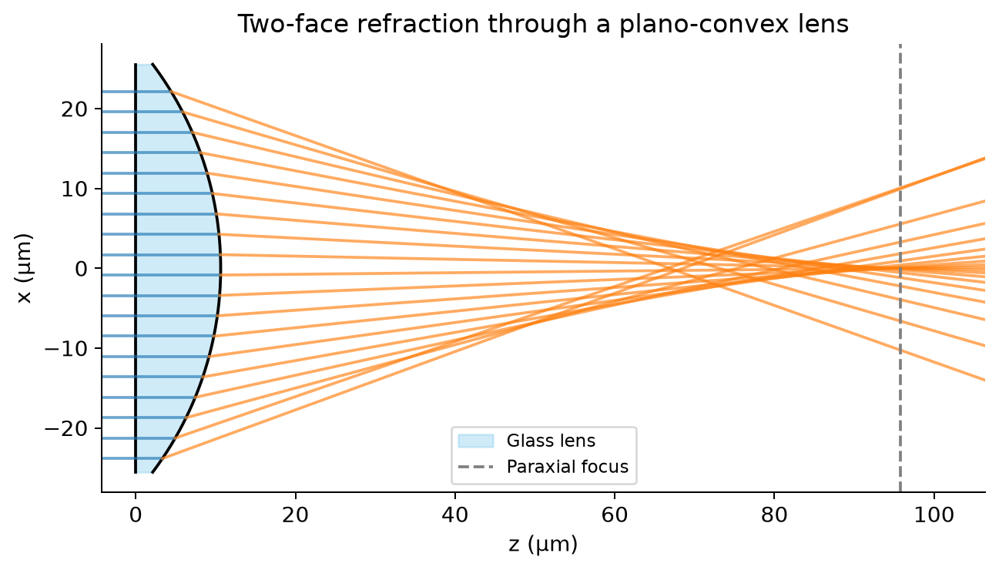

In [3]:
entrance, exit_face = solution.encounters[0]
exit_points = exit_face.grid.points
directions = exit_face.transmitted_directions
meridian = np.linspace(-aperture, aperture, 300)
exit_z = thickness + back.height(np.column_stack((meridian, np.zeros_like(meridian))))

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
ax.fill_betweenx(
    meridian / um, 0, exit_z / um, color="skyblue", alpha=0.4, label="Glass lens"
)
ax.plot(exit_z / um, meridian / um, color="black")
ax.plot(np.zeros_like(meridian), meridian / um, color="black")

for column in range(0, grid_size, 6):
    point = exit_points[grid_size // 2, column]
    if abs(point[0]) >= 0.95 * aperture:
        continue
    direction = directions[grid_size // 2, column]
    end_z = paraxial_focus + 20 * wavelength
    end_x = point[0] + (end_z - point[2]) * direction[0] / direction[2]
    ax.plot(
        [-8 * wavelength / um, point[2] / um],
        [point[0] / um] * 2,
        color="tab:blue",
        alpha=0.65,
    )
    ax.plot(
        [point[2] / um, end_z / um],
        [point[0] / um, end_x / um],
        color="tab:orange",
        alpha=0.65,
    )

ax.axvline(paraxial_focus / um, color="gray", ls="--", label="Paraxial focus")
ax.set(
    xlabel="z (µm)",
    ylabel="x (µm)",
    title="Two-face refraction through a plano-convex lens",
    aspect="equal",
)
ray_z_limits = (-8 * wavelength / um, (paraxial_focus + 20 * wavelength) / um)
ray_x_limits = (-1.1 * aperture / um, 1.1 * aperture / um)
ax.set(xlim=ray_z_limits, ylim=ray_x_limits)
ax.legend(fontsize=9)
plt.show()

## Observe the beam approaching and passing through focus

The field is evaluated from the outgoing angular spectrum obtained by
$Q^{-1}TQ$. Equal-lattice parallel planes use FFT ASM; arbitrary observation
points use a nonuniform Fourier sum (FINUFFT when installed). The longitudinal
map is displayed separately, with physical electric-field units.


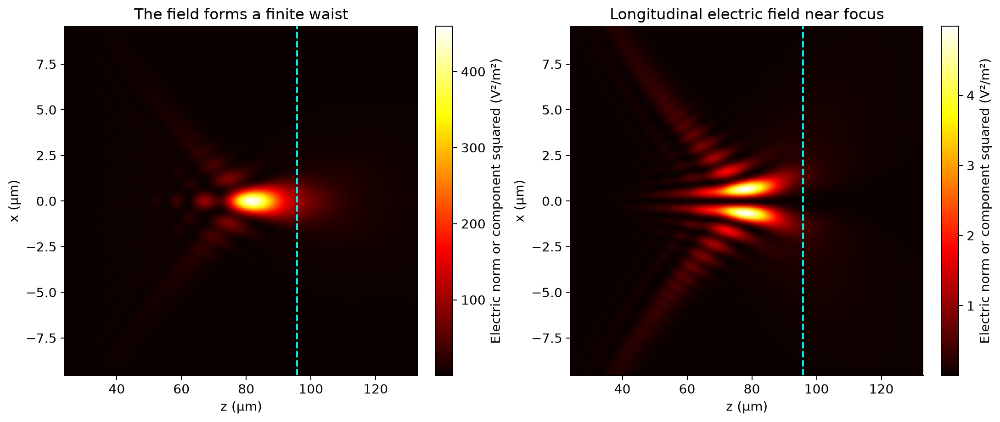

Paraxial focus: 95.76 µm; sampled wave-field peak: 81.88 µm


In [4]:
x = np.linspace(-18, 18, 161) * wavelength
z = np.linspace(thickness + 25 * wavelength, thickness + 230 * wavelength, 321)
X, Z = np.meshgrid(x, z)


points = np.stack((X, np.zeros_like(X), Z), axis=-1)  # xz plane.
meridional_field = solution.evaluate(optics.PointGrid(points))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, values, title in (
    (axes[0], meridional_field.electric.norm2(), "The field forms a finite waist"),
    (
        axes[1],
        abs(meridional_field.electric.Ez) ** 2,
        "Longitudinal electric field near focus",
    ),
):
    image = ax.pcolormesh(z / um, x / um, values.T, cmap="hot", shading="gouraud")
    ax.axvline(paraxial_focus / um, color="cyan", ls="--")
    ax.set(xlabel="z (µm)", ylabel="x (µm)", title=title)
    fig.colorbar(image, ax=ax, label="Electric norm or component squared (V²/m²)")

plt.show()

axial_norm = meridional_field.electric.norm2()[:, len(x) // 2]
focus_z = z[np.argmax(axial_norm)]
print(
    f"Paraxial focus: {paraxial_focus / um:.2f} µm; sampled wave-field peak: {focus_z / um:.2f} µm"
)

A spherical surface has spherical aberration, and a finite aperture also shifts
the wave-field peak. The next plots use the sampled axial maximum, not a fitted
phase or gain. For x-polarized input, $E_z$ is antisymmetric across x; its squared
magnitude therefore has two lobes even though the main focal spot is centered.

## Inspect the focal plane and its energy flow

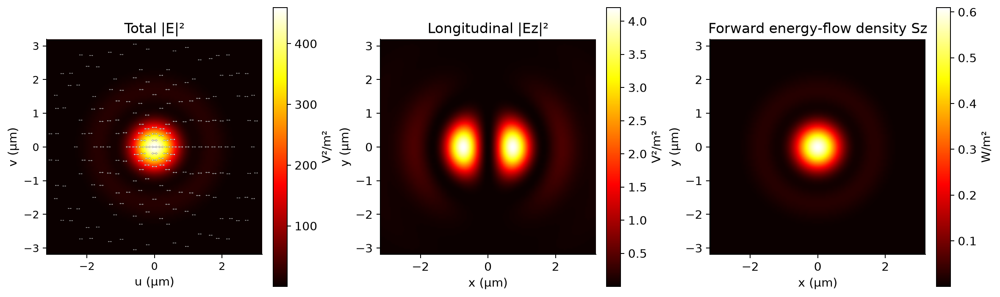

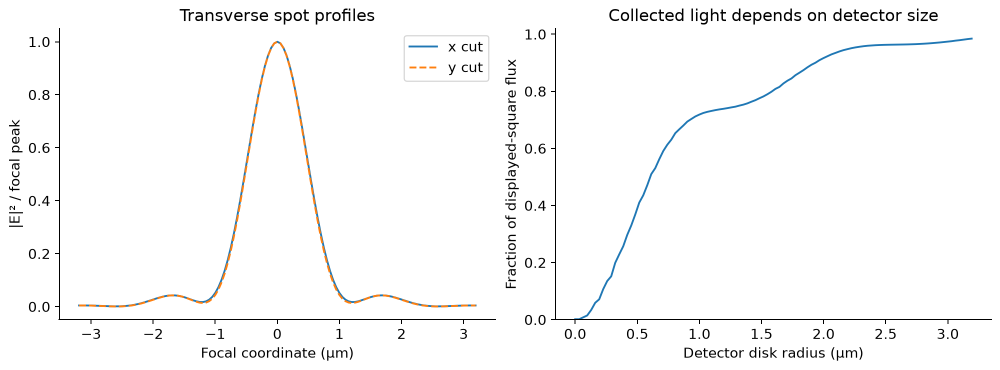

In [5]:
focal_axis = np.linspace(-6, 6, 129) * wavelength
FX, FY = np.meshgrid(focal_axis, focal_axis)
focal_grid = optics.CartesianGrid(focal_axis, focal_axis, optics.Frame([0, 0, focus_z]))
focal = solution.evaluate(focal_grid)
peak = np.max(focal.electric.norm2())

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
components = (
    (focal.electric.norm2(), "Total |E|²"),
    (abs(focal.electric.Ez) ** 2, "Longitudinal |Ez|²"),
    (focal.poynting()[..., 2], "Forward energy-flow density Sz"),
)

for ax, (values, title) in zip(axes, components):
    image = ax.pcolormesh(
        focal_axis / um, focal_axis / um, values, cmap="hot", shading="gouraud"
    )
    ax.set(xlabel="x (µm)", ylabel="y (µm)", title=title, aspect="equal")
    if title == "Total |E|²":
        plot_polarization(
            focal,
            axis=ax,
            distribution="polar",
            background=False,
            colorbar=False,
            legend=False,
            crop=False,
            title=title,
        )
    fig.colorbar(image, ax=ax, label="W/m²" if "Sz" in title else "V²/m²")

plt.show()

center = len(focal_axis) // 2
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(focal_axis / um, focal.electric.norm2()[center] / peak, label="x cut")
axes[0].plot(
    focal_axis / um, focal.electric.norm2()[:, center] / peak, "--", label="y cut"
)
axes[0].set(
    xlabel="Focal coordinate (µm)",
    ylabel="|E|² / focal peak",
    title="Transverse spot profiles",
)
axes[0].legend()

flow = focal.poynting()[..., 2]
radii = np.linspace(0, 6, 100) * wavelength
fraction = [flow[FX**2 + FY**2 <= radius**2].sum() / flow.sum() for radius in radii]
axes[1].plot(radii / um, fraction)
axes[1].set(
    xlabel="Detector disk radius (µm)",
    ylabel="Fraction of displayed-square flux",
    title="Collected light depends on detector size",
    ylim=(0, 1.02),
)
plt.show()

The two component maps have separate, labeled scales; a bright longitudinal
panel does not mean Ez is as large as Ex. The encircled fraction is relative to
the finite displayed detector square, not the incident beam's total power.

Before interpreting a small focal feature, refine the Cartesian lattice at
fixed physical observation points. This checks discretization of the
chosen physical-optics model; it cannot remove that model's boundary error.

In [6]:
probes = optics.PointGrid(
    np.array(
        [
            [0, 0, focus_z],
            [wavelength, 0, focus_z],
            [0, wavelength, focus_z],
            [0, 0, focus_z + 2 * wavelength],
        ]
    )
)
refined_grid = tangent_grid(192)
refined = optics.propagate_interfaces(source, lens, refined_grid)
reference = refined.evaluate(probes).electric.values
actual = solution.evaluate(probes).electric.values
relative_change = np.linalg.norm(actual - reference) / np.linalg.norm(reference)
print(
    f"Complex E change, {grid_size}² → {refined_grid.shape[0]}² Cartesian samples: {relative_change:.3g}"
)
assert relative_change < 0.02

Complex E change, 160² → 192² Cartesian samples: 5.95e-05


**Try next:** increase the aperture to see stronger spherical aberration and
longitudinal fields, or reduce it to broaden the diffraction spot. Keep enough
central thickness that the faces do not intersect. Repeat the grid and padding checks
after changing geometry. A useful next lens design is an aspheric exit face,
compared at the same illumination, aperture and detector coordinates.

## Matched lens: replace only the spherical exit face

Both lenses now have the same plane entrance, glass, air surroundings, central
thickness, clear diameter, incident Gaussian beam and polarization. Their exit
faces have the same **signed vertex radius** $R=-80\lambda_0$. A stigmatic asphere
has varying curvature away from the vertex, so its edge sag necessarily differs
from the sphere. “Same size” here means the same diameter and central thickness;
it does not mean identical edge thickness or glass volume.

The nominal design illumination inside the lens is collimated. The appropriate
GOTS design has $z_0=-\infty$, rather than a finite object chosen arbitrarily.
For the glass-to-air exit interface, $n_o=1.5$ and $n_i=1$. Its local image
coordinate is fixed by the shared vertex curvature:

$$
z_i=\frac{n_i R}{n_i-n_o},\qquad
G=-\left(\frac{n_o}{n_i}\right)^2,\quad
O=\frac{n_i}{z_i(n_i-n_o)}=\frac1R,\quad T=S=0.
$$

These are the analytic $z_0\to-\infty$ limits of the finite-conjugate GOTS
coefficients from thesis Appendix D, D.5–D.8. The same parametric expression is used:

$$
z(\rho)=\frac{O\rho^2}{1+\sqrt{1-O^2G\rho^2}},\qquad
r(\rho)=\sqrt{\rho^2-z(\rho)^2}.
$$

$\rho$ remains distance from the vertex, not cylindrical aperture radius.
The frame places the exit vertex at the same global `thickness` as the sphere.
Both lenses consequently share the same paraxial image position. No amplitude,
phase, aperture or focal-length fitting is used.


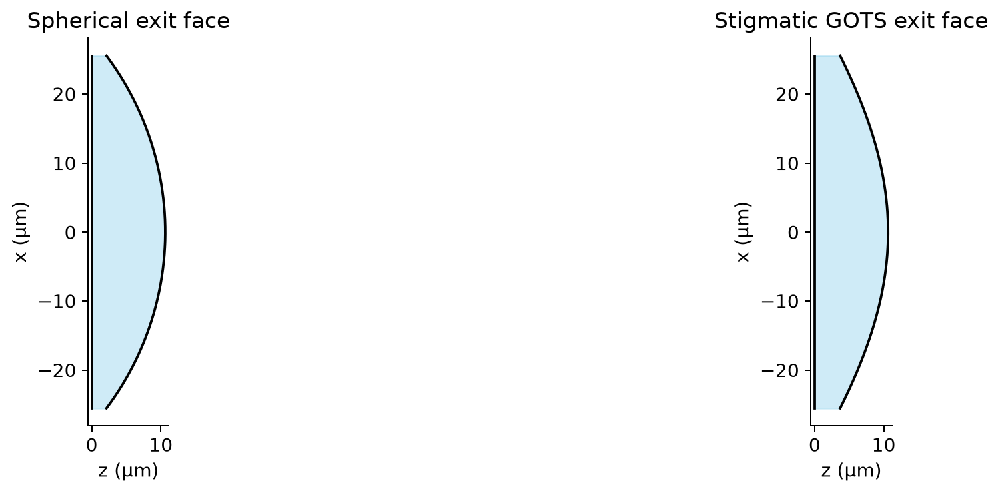

Shared signed vertex radius: -42.560 µm
Shared diameter: 51.072 µm; central thickness: 10.640 µm
Spherical edge optical-path error at the shared image: -1.572 wavelengths


In [7]:
no, ni = glass.material.n, exit_air.material.n
z0 = -np.inf
zi = ni * back.radius / (ni - no)
oval = optics.CartesianOval.from_conjugates(no, z0, ni, zi, frame=back.frame)
G, O, T, S = oval.gots  # noqa: E741 - GOTS notation
image_z = thickness + zi
image_point = np.array([0, 0, image_z])

assert np.isclose(O, 1 / back.radius)
assert np.isclose(image_z, paraxial_focus)

rho = np.linspace(0, oval.rho_from_r(aperture), 80)
phi = np.linspace(0, 2 * np.pi, 65)
shape = oval.parametric_points(rho[:, None], phi[None, :])
profile_xy = np.column_stack((meridian, np.zeros_like(meridian)))
oval_exit_z = thickness + oval.height(profile_xy)
assert np.all(oval_exit_z > 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, height, title in (
    (axes[0], exit_z, "Spherical exit face"),
    (axes[1], oval_exit_z, "Stigmatic GOTS exit face"),
):
    ax.fill_betweenx(meridian / um, 0, height / um, color="skyblue", alpha=0.4)
    ax.plot(height / um, meridian / um, color="black")
    ax.plot(np.zeros_like(meridian), meridian / um, color="black")
    ax.set(
        xlabel="z (µm)",
        ylabel="x (µm)",
        title=title,
        xlim=(-wavelength / um, (thickness + wavelength) / um),
        ylim=ray_x_limits,
        aspect="equal",
    )

plt.show()
print(f"Shared signed vertex radius: {back.radius / um:.3f} µm")
print(
    f"Shared diameter: {2 * aperture / um:.3f} µm; central thickness: {thickness / um:.3f} µm"
)

sphere_local_z = back.height(profile_xy)
sphere_distance = np.hypot(meridian, zi - sphere_local_z)
sphere_path_error = (no * sphere_local_z + ni * sphere_distance - ni * zi) / wavelength
print(
    f"Spherical edge optical-path error at the shared image: {sphere_path_error[0]:.3f} wavelengths"
)

### The same beam through both lenses

The source and entrance lattice are reused unchanged. Both optical systems
include transmission through the plane entrance and refraction at the exit.
The ray panels use identical physical axes, including the lens and image plane.


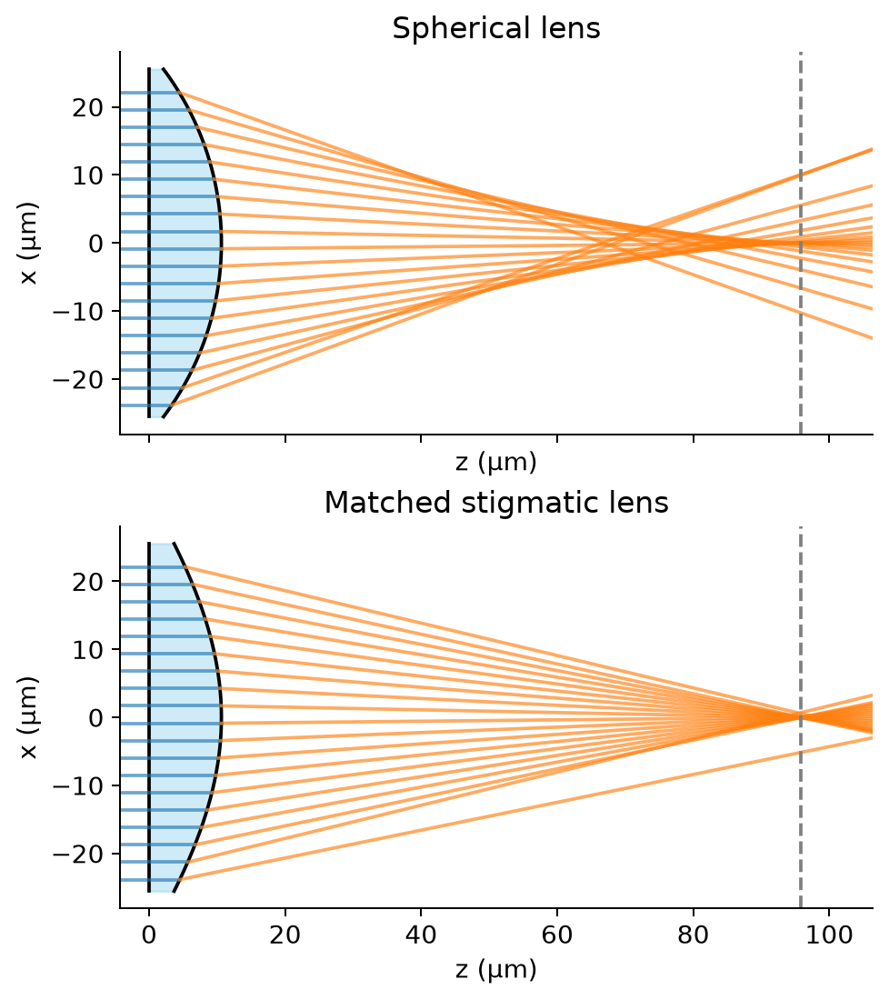

Optical-path error: 5.09e-14 wavelengths; ray-direction error: 0.00265
Local exit-interface power imbalance: 0


In [8]:
oval_system = optics.OpticalSystem(
    (
        optics.DielectricInterface(front, air, glass),
        optics.DielectricInterface(oval, glass, exit_air),
    ),
    (aperture, aperture),
)
oval_solution = optics.propagate_interfaces(source, oval_system, entrance_grid)

fig, axes = plt.subplots(
    2, 1, figsize=(12, 6), sharex=True, sharey=True, layout="constrained"
)
for ax, current, profile, title in (
    (axes[0], solution, exit_z, "Spherical lens"),
    (axes[1], oval_solution, oval_exit_z, "Matched stigmatic lens"),
):
    encounter = current.encounters[0][-1]
    q = encounter.grid.points
    directions = encounter.transmitted_directions
    ax.fill_betweenx(meridian / um, 0, profile / um, color="skyblue", alpha=0.4)
    ax.plot(profile / um, meridian / um, color="black")
    ax.plot(np.zeros_like(meridian), meridian / um, color="black")

    for column in range(0, grid_size, 6):
        point = q[grid_size // 2, column]
        if abs(point[0]) >= 0.95 * aperture:
            continue
        direction = directions[grid_size // 2, column]
        end_z = ray_z_limits[1] * um
        end_x = point[0] + (end_z - point[2]) * direction[0] / direction[2]
        ax.plot(
            [ray_z_limits[0], point[2] / um],
            [point[0] / um] * 2,
            color="tab:blue",
            alpha=0.65,
        )
        ax.plot(
            [point[2] / um, end_z / um],
            [point[0] / um, end_x / um],
            color="tab:orange",
            alpha=0.65,
        )

    ax.axvline(image_z / um, color="gray", ls="--")
    ax.set(
        xlabel="z (µm)",
        ylabel="x (µm)",
        title=title,
        xlim=ray_z_limits,
        ylim=ray_x_limits,
        aspect="equal",
    )

plt.show()

encounter = oval_solution.encounters[0][-1]
q = encounter.grid.points
local_z = q[..., 2] - thickness
path = no * local_z + ni * np.linalg.norm(image_point - q, axis=-1)
inside = np.linalg.norm(q[..., :2], axis=-1) <= aperture
path_error = np.max(abs(path[inside] - ni * zi)) / wavelength
expected_direction = image_point - q
expected_direction /= np.linalg.norm(expected_direction, axis=-1, keepdims=True)
ray_direction = encounter.transmitted_directions
weights = encounter.transmitted.electric.norm2()
ray_error = np.sqrt(
    np.sum(weights * np.sum((ray_direction - expected_direction) ** 2, axis=-1))
    / weights.sum()
)
flux_error = (
    abs(
        encounter.incident.power()
        + encounter.reflected.power()
        - encounter.transmitted.power()
    )
    / encounter.incident.power()
)
print(
    f"Optical-path error: {path_error:.3g} wavelengths; ray-direction error: {ray_error:.3g}"
)
print(f"Local exit-interface power imbalance: {flux_error:.3g}")
assert path_error < 1e-10
assert (
    ray_error < 0.01
)  # incident diffraction slightly perturbs the nominal collimated design
assert flux_error < 1e-10

### Compare propagation on exactly the same coordinates

Both solutions are evaluated on the original `(x, z)` grid. Each column uses
one shared color scale across the two lenses, with no peak normalization.
The dashed line marks their shared paraxial image position. Geometrical
stigmatism does not remove diffraction or force the wave-field maximum to lie
exactly at that plane.


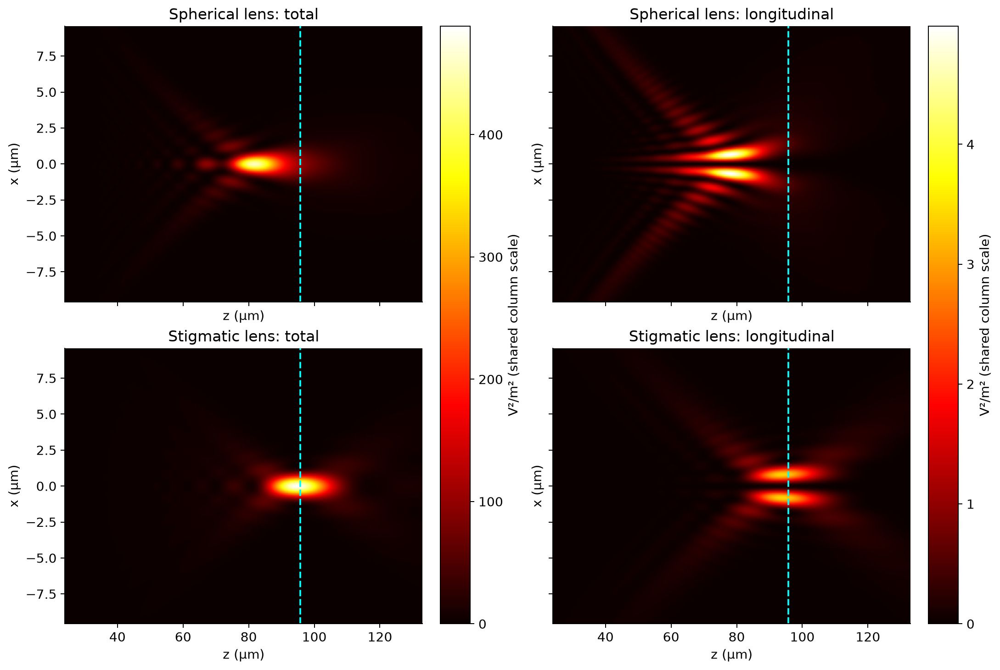

In [9]:
comparison_grid = optics.PointGrid(np.stack((X, np.zeros_like(X), Z), axis=-1))
oval_section = oval_solution.evaluate(comparison_grid)
sections = (meridional_field, oval_section)
titles = ("Spherical lens", "Stigmatic lens")

fig, axes = plt.subplots(
    2, 2, figsize=(12, 8), sharex=True, sharey=True, layout="constrained"
)
for column, component in enumerate(("total", "longitudinal")):
    maps = [
        field.electric.norm2() if component == "total" else abs(field.electric.Ez) ** 2
        for field in sections
    ]
    maximum = max(values.max() for values in maps)

    for row, (values, title) in enumerate(zip(maps, titles)):
        im = axes[row, column].pcolormesh(
            z / um,
            x / um,
            values.T,
            shading="gouraud",
            cmap="hot",
            vmin=0,
            vmax=maximum,
        )
        axes[row, column].axvline(image_z / um, color="cyan", ls="--")
        axes[row, column].set(
            xlabel="z (µm)",
            ylabel="x (µm)",
            title=f"{title}: {component}",
            xlim=(z[0] / um, z[-1] / um),
            ylim=(x[0] / um, x[-1] / um),
        )

    fig.colorbar(im, ax=axes[:, column], label="V²/m² (shared column scale)")

plt.show()

### Compare both fields in the same image plane

Use the common **geometrical image plane**, not each lens's separately selected
axial maximum. The transverse coordinates equal those of the earlier focal
plots. Each observable has a common color scale across both lenses. This keeps
changes in spot shape and absolute field strength visible without moving the
detector or rescaling either solution.


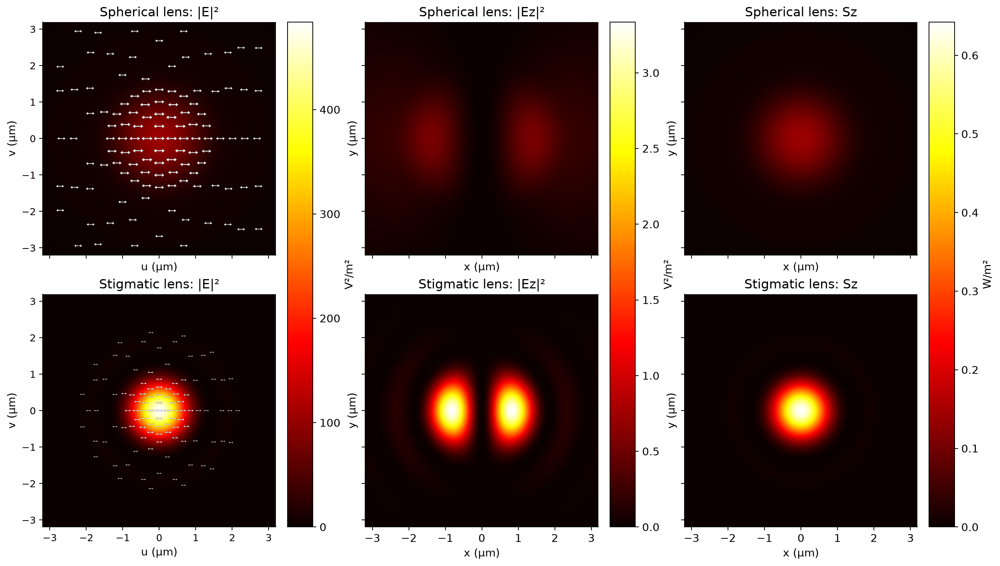

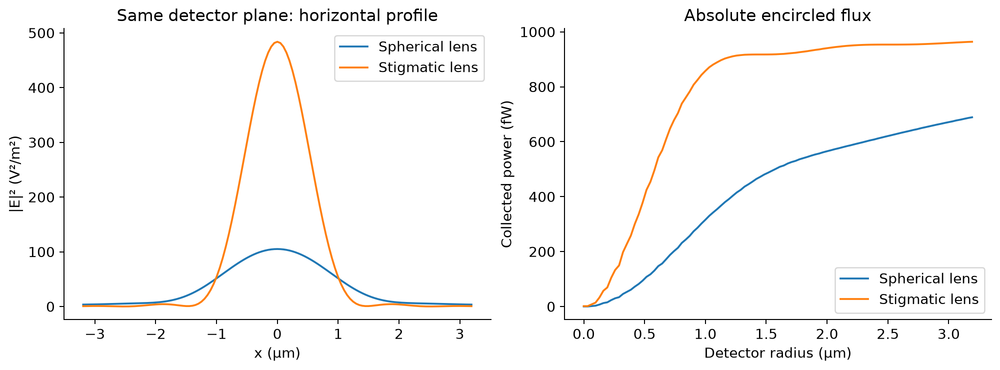

On-axis |E|² at the shared image plane: sphere=105.1, stigmatic=483.8 V²/m²
Stigmatic / spherical on-axis |E|²: 4.605


In [10]:
matched_grid = optics.CartesianGrid(
    focal_axis, focal_axis, optics.Frame([0, 0, image_z])
)
matched_fields = (solution.evaluate(matched_grid), oval_solution.evaluate(matched_grid))
fig, axes = plt.subplots(
    2, 3, figsize=(14, 8), sharex=True, sharey=True, layout="constrained"
)

for column, label in enumerate(("|E|²", "|Ez|²", "Sz")):
    maps = [
        (field.electric.norm2(), abs(field.electric.Ez) ** 2, field.poynting()[..., 2])[
            column
        ]
        for field in matched_fields
    ]
    minimum = min(0, min(values.min() for values in maps))
    maximum = max(values.max() for values in maps)

    for row, (values, title) in enumerate(zip(maps, titles)):
        im = axes[row, column].pcolormesh(
            focal_axis / um,
            focal_axis / um,
            values,
            shading="gouraud",
            cmap="hot",
            vmin=minimum,
            vmax=maximum,
        )
        axes[row, column].set(
            xlabel="x (µm)",
            ylabel="y (µm)",
            title=f"{title}: {label}",
            aspect="equal",
            xlim=(focal_axis[0] / um, focal_axis[-1] / um),
            ylim=(focal_axis[0] / um, focal_axis[-1] / um),
        )

        if column == 0:
            plot_polarization(
                matched_fields[row],
                axis=axes[row, column],
                distribution="polar",
                background=False,
                colorbar=False,
                legend=False,
                crop=False,
                title=f"{title}: {label}",
            )

    fig.colorbar(im, ax=axes[:, column], label="W/m²" if label == "Sz" else "V²/m²")

plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for field, title in zip(matched_fields, titles):
    axes[0].plot(focal_axis / um, field.electric.norm2()[center], label=title)
    flow = field.poynting()[..., 2]
    pixel_area = (focal_axis[1] - focal_axis[0]) ** 2
    collected = [
        pixel_area * flow[FX**2 + FY**2 <= radius**2].sum() for radius in radii
    ]
    axes[1].plot(radii / um, np.asarray(collected) * 1e15, label=title)

axes[0].set(
    xlabel="x (µm)",
    ylabel="|E|² (V²/m²)",
    title="Same detector plane: horizontal profile",
)
axes[1].set(
    xlabel="Detector radius (µm)",
    ylabel="Collected power (fW)",
    title="Absolute encircled flux",
)
for ax in axes:
    ax.legend()

plt.show()

sphere_center = matched_fields[0].electric.norm2()[center, center]
oval_center = matched_fields[1].electric.norm2()[center, center]
print(
    f"On-axis |E|² at the shared image plane: sphere={sphere_center:.4g}, stigmatic={oval_center:.4g} V²/m²"
)
print(f"Stigmatic / spherical on-axis |E|²: {oval_center / sphere_center:.3f}")

### Polarization on the common detector

The ellipse maps use the same detector coordinates and field values as above.
Their backgrounds have independent labeled scales to reveal polarization in
both fields; use the earlier shared-scale maps for the absolute brightness
comparison. These glyphs show the transverse projection only. The longitudinal
component remains visible in the component maps above.

This figure uses a declared **square-root display normalization**
(`intensity_gamma=0.5`). Exact zeros remain black while weak diffraction rings
remain visible. The renderer interpolates the raster between the computed grid
samples only for display; the exact, unsmoothed samples appear in the horizontal
profile above.
That profile confirms that spherical aberration fills the spherical lens's
radial zeros at this common detector plane, whereas the stigmatic lens retains
deep diffraction minima.

We request `distribution="polar"` so glyph centers lie on exact concentric rings.
Every radial station is retained; weak rings reduce angular density instead of
opening radial gaps. The underlying Cartesian field is linearly interpolated as
complex components at these display positions; its sampling and propagation are
unchanged. The default relative glyph radius is
$0.5 + 0.5 (I/I_{\\max})^{1/4}$, retaining readable polarization in weak rings.
Use `scale_by_intensity=False` for uniform sizes.

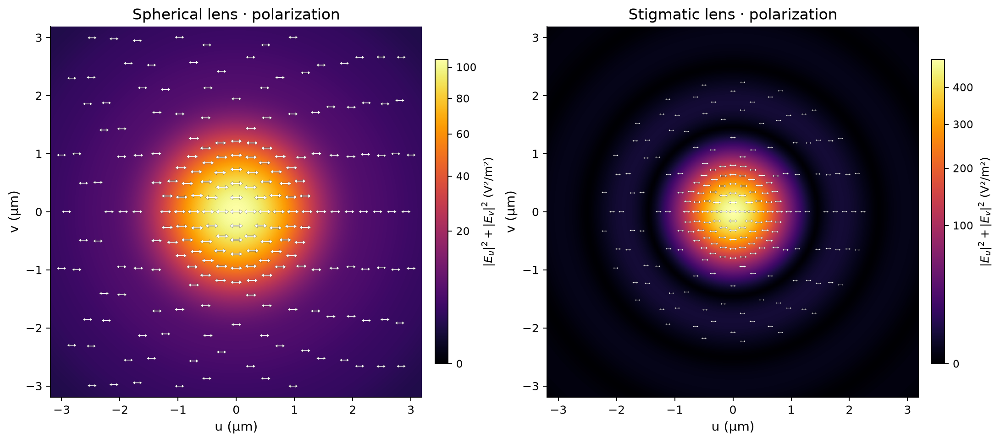

In [11]:
from vecdiff_general.visualization import plot_polarization

figure, axes = plt.subplots(1, 2, figsize=(12, 5.7), layout="constrained")

for axis, current_field, title in zip(
    axes,
    (matched_fields[0], matched_fields[1]),
    ("Spherical lens · polarization", "Stigmatic lens · polarization"),
):
    plot_polarization(
        current_field,
        axis=axis,
        title=title,
        distribution="polar",
        intensity_gamma=0.5,
        crop=False,
    )
plt.show()

### Follow the optical cycle at the stigmatic focus

The earlier comparison used the same linearly polarized source for both lenses.
Here, illuminate the **same stigmatic lens** with circular polarization at the
same incident electric norm. Propagate this new source through both interfaces
and evaluate it on the unchanged detector. Local Fresnel transmission and
vectorial diffraction can change the polarization, especially in secondary rings.

The static map puts tangent heads away from the ellipse's major axis. In the
movie, each electric arrow starts at the fixed ellipse center and ends on its
ellipse at the actual local phase. The head aligns with the shaft, and there
are no point markers. All positions share the same time. A stronger display contrast reveals weaker
rings without rescaling the field or altering the earlier lens comparison.

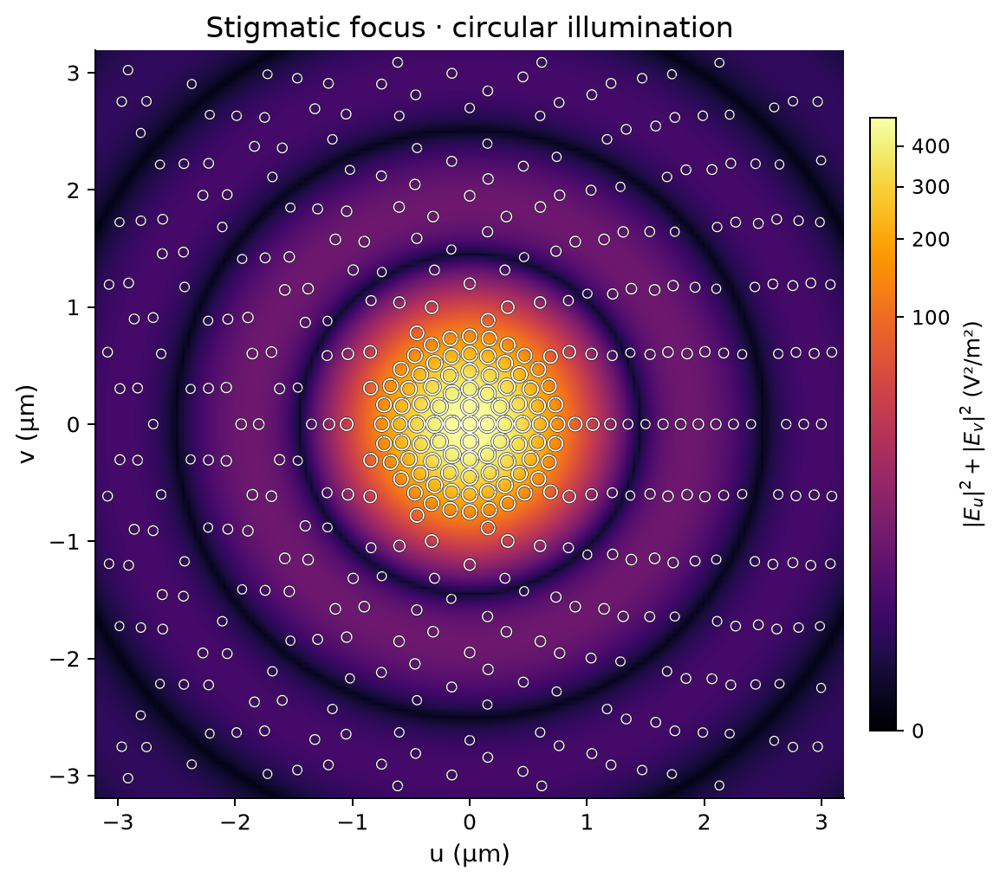

In [12]:
from IPython.display import HTML, display
from vecdiff_general.visualization import animate_polarization, plot_polarization


def circular_envelope(points):
    amplitude = pupil_amplitude(points)

    return amplitude[..., None] * np.array([1, 1j, 0]) / np.sqrt(2)


circular_source = optics.EikonalField(
    optical_path=source.optical_path,
    path_gradient=source.path_gradient,
    envelope=circular_envelope,
    wavelength0=wavelength,
    region=air,
)
circular_solution = optics.propagate_interfaces(
    circular_source, oval_system, entrance_grid
)
circular_focus = circular_solution.evaluate(matched_grid)

plot_polarization(
    circular_focus,
    distribution="polar",
    crop=False,
    intensity_gamma=0.25,
    min_intensity_fraction=1e-4,
    title="Stigmatic focus · circular illumination",
)
plt.show()

plt.rcParams["animation.embed_limit"] = 64  # MB; retain the complete cycle.
animation = animate_polarization(
    circular_focus,
    distribution="polar",
    frames=48,
    crop=False,
    intensity_gamma=0.25,
    min_intensity_fraction=1e-4,
    title="Stigmatic focus · one optical cycle",
)
display(HTML(animation.to_jshtml()))
plt.close(animation._fig)

### Check sampling, padding, boundary reconstruction and flux

Refine the entrance lattice at fixed observation points, then enlarge its
periodic cell at fixed spacing. The inverse fits tangential electric data.
The reconstructed magnetic trace provides an independent check of the local
Fresnel approximation; it need not coincide with the local plane-wave trace.
No gain or flux renormalization is applied.


In [13]:
probe_grid = optics.PointGrid(
    np.array(
        [
            [0, 0, image_z],
            [wavelength, 0, image_z],
            [0, wavelength, image_z],
            [0, 0, image_z + wavelength],
        ]
    )
)
refined_oval_solution = optics.propagate_interfaces(source, oval_system, refined_grid)
reference = refined_oval_solution.evaluate(probe_grid).electric.values
actual = oval_solution.evaluate(probe_grid).electric.values
oval_change = np.linalg.norm(actual - reference) / np.linalg.norm(reference)
print(f"Stigmatic complex-field grid change: {oval_change:.3g}")
assert oval_change < 0.01

# Include off-axis and near-lens points, not only the bright focus.
probe_x = x[np.linspace(0, len(x) - 1, 5, dtype=int)]
probe_z = z[np.linspace(0, len(z) - 1, 5, dtype=int)]
PX, PZ = np.meshgrid(probe_x, probe_z)
map_probes = optics.PointGrid(np.stack((PX, np.zeros_like(PX), PZ), axis=-1))

for coarse, fine, title in (
    (solution, refined, "Spherical lens"),
    (oval_solution, refined_oval_solution, "Stigmatic lens"),
):
    reference = fine.evaluate(map_probes).electric.values
    actual = coarse.evaluate(map_probes).electric.values
    error = np.linalg.norm(actual - reference, axis=-1)
    reference_scale = np.max(np.linalg.norm(reference, axis=-1))
    map_error = np.max(error) / reference_scale
    print(f"{title}: map-probe complex-field refinement error {map_error:.3g}")
    assert map_error < 0.005
# Padding is a separate error source from sample spacing.
padded_grid = tangent_grid(240, 192 * wavelength)
for system, current, title in (
    (lens, solution, "Sphere"),
    (oval_system, oval_solution, "Oval"),
):
    padded = optics.propagate_interfaces(source, system, padded_grid)
    a = current.evaluate(probe_grid).electric.values
    b = padded.evaluate(probe_grid).electric.values
    padding_error = np.linalg.norm(a - b) / np.linalg.norm(b)
    print(f"{title}: 128λ → 192λ cell change {padding_error:.3g}")
    assert padding_error < 0.01
    Q = current.transports[-1][1]
    reconstructed = Q.forward(current.transmitted[0])
    target = current.encounters[0][-1].transmitted
    magnetic_error = np.linalg.norm(
        reconstructed.magnetic - target.magnetic
    ) / np.linalg.norm(target.magnetic)
    flux_error = abs(reconstructed.power() / target.power() - 1)
    report = current.inverse_reports[0][-1]
    print(
        f"{title}: Q rank {Q.rank}, inverse iterations {report.iterations}, tangential E residual {report.relative_residual:.3g}"
    )
    print(
        f"{title}: reconstructed H error {magnetic_error:.3g}, flux error {flux_error:.3g}"
    )
    assert report.relative_residual < 0.002
    assert magnetic_error < 0.03
    assert flux_error < 0.002

Stigmatic complex-field grid change: 3.34e-05


Spherical lens: map-probe complex-field refinement error 0.000467


Stigmatic lens: map-probe complex-field refinement error 0.000555


Sphere: 128λ → 192λ cell change 0.000137
Sphere: Q rank 33, inverse iterations 40, tangential E residual 0.00019
Sphere: reconstructed H error 0.0195, flux error 0.000189


Oval: 128λ → 192λ cell change 2.07e-05
Oval: Q rank 29, inverse iterations 26, tangential E residual 4.93e-05
Oval: reconstructed H error 0.0116, flux error 5e-05


**Explore:** change the shared curvature radius, aperture, thickness or beam
waist at the top, then rerun both lenses. Recompute `zi` from the curvature;
choosing it independently would break the matched comparison. Keep both exit
faces ahead of the plane entrance over the full clear aperture.

Finite real conjugates remain supported by `CartesianOval.from_conjugates`.
The explicit `z0=-np.inf` limit is used here because it matches the original
collimated illumination. The separate `stigmatic/` implementation is unchanged.
